# 05 — Time-Resolved Corrosion Kinetics, Time to Threshold & Thickness Loss Risk

This notebook demonstrates the Phase 2 time-resolved kinetics and risk workflow (`corrosion_simulator.kinetics`):
1. Modeling cumulative **Corrosion Depth** $d(t)$ anchored at $t = 0$ to Faraday **Initial Corrosion Rate ($\text{CR}_0$)** via Linear, Passivation, and Power-law models (ADR-0002).
2. Automatic default kinetic regime selection from Pourbaix stability indicators (`Active` $\to$ Linear, `Passivation` $\to$ Passivation, `Transitional`/`Inhibited` $\to$ Power-law).
3. Computing **Time to Threshold** for a configurable **Critical Thickness Threshold ($d_{\text{crit}} = 1.0\text{ nm}$)**, including unreached ($\infty$) passivation limits.
4. Evaluating continuous **Thickness Loss Risk** $R(t) \in [0, 1]$ and discrete tiers (`Low`, `Medium`, `High`, `Critical`) with Monte Carlo uncertainty bands for both isolated and galvanically coupled metals.


In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from corrosion_simulator import (
    HarmonizedDatabase,
    HybridMLPredictor,
    MLFeatureQuery,
    PolarizationParameters,
    calculate_faraday_corrosion_rate,
    compare_kinetic_models,
    plot_kinetics_and_risk,
    propagate_galvanic_uncertainty_monte_carlo,
    propagate_kinetics_uncertainty_monte_carlo,
    propagate_uncertainty_monte_carlo,
    select_kinetic_model_from_pourbaix,
    simulate_time_resolved_kinetics,
    solve_galvanic_couple,
)

seed_db = HarmonizedDatabase.from_seed()
print("Loaded seed HarmonizedDatabase for reproducible time-resolved kinetics demonstration.")


Loaded seed HarmonizedDatabase for reproducible time-resolved kinetics demonstration.


## 1. Pourbaix-Based Automatic Kinetic Regime Selection

We inspect how different metals and solution pH / inhibitor conditions map onto the three kinetic regimes.


In [2]:
cases = [
    ("Co", 2.0, False),
    ("Co", 2.0, True),
    ("Cu", 4.0, False),
    ("Cu", 10.0, True),
    ("Ti", 6.0, False),
    ("Ta", 5.0, False),
    ("W", 7.0, False),
]
rows = []
for metal, ph, has_inh in cases:
    sel = select_kinetic_model_from_pourbaix(
        metal=metal, pH=ph, inhibitor_present=has_inh, material_properties=seed_db.material_properties
    )
    rows.append({
        "Metal": metal,
        "pH": ph,
        "Inhibitor": has_inh,
        "Pourbaix Regime": sel.regime,
        "Selected Model": sel.model,
    })
print(pd.DataFrame(rows).to_string(index=False))


Metal   pH  Inhibitor Pourbaix Regime Selected Model
   Co  2.0      False          Active         linear
   Co  2.0       True       Inhibited      power_law
   Cu  4.0      False          Active         linear
   Cu 10.0       True       Inhibited      power_law
   Ti  6.0      False     Passivation    passivation
   Ta  5.0      False     Passivation    passivation
    W  7.0      False          Active         linear


## 2. Multi-Model Comparison Anchored to $\text{CR}_0$

Starting from a coupled Co/Cu galvanic **Initial Corrosion Rate ($\text{CR}_0$)**, we compare Linear, Passivation ($d_{\max} = 5.0\text{ nm}$), and Power-law ($n = 0.6, t_{\text{ref}} = 60\text{ s}$) trajectories over 5 minutes ($300\text{ s}$) against $d_{\text{crit}} = 1.0\text{ nm}$.


      Model  CR_0 (nm/min)  Time to d_crit=1nm (s)  Depth @ 300s (nm)  Risk R(300s) Final Tier
     linear        15.3071                    3.92             76.536         1.000   Critical
passivation        15.3071                    4.37              5.000         0.969   Critical
  power_law        15.3071                    0.64             40.205         1.000   Critical


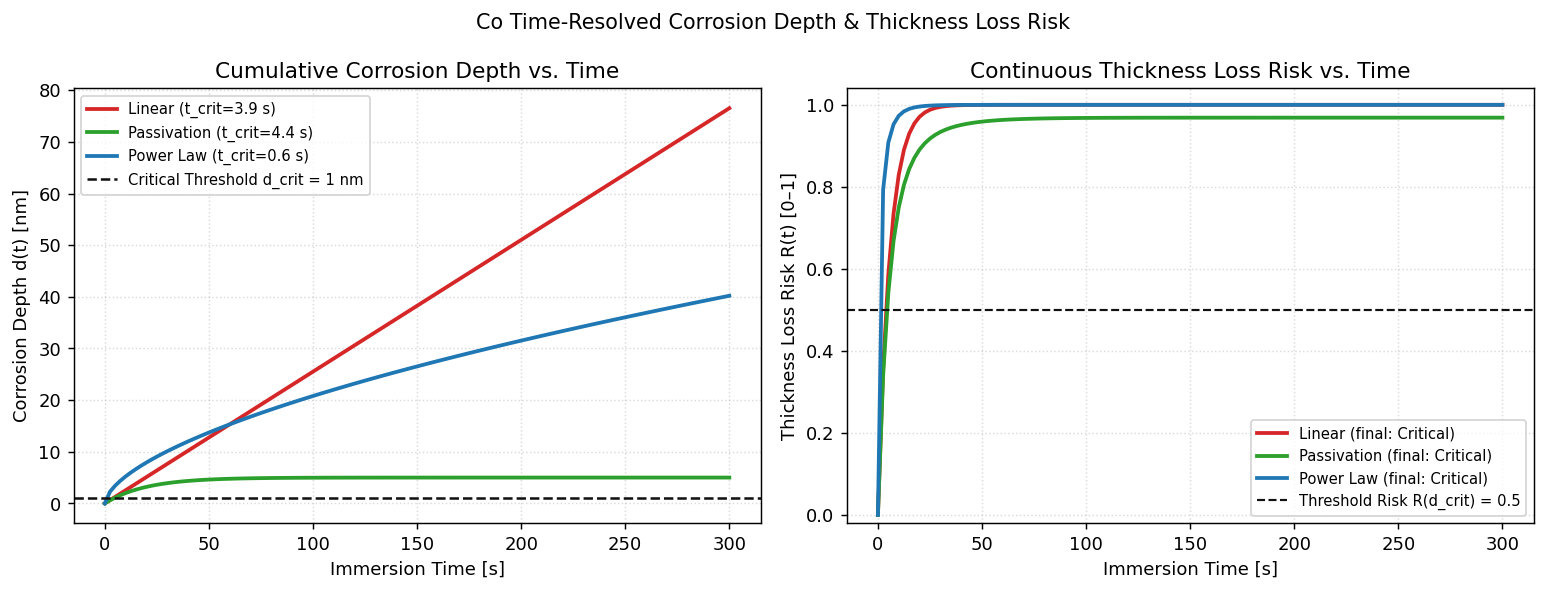

In [3]:
co_p = PolarizationParameters(Ecorr_V_SHE=-0.120, icorr_uA_cm2=12.0, beta_a_mV_dec=65.0, beta_c_mV_dec=120.0, metal="Co")
cu_p = PolarizationParameters(Ecorr_V_SHE=0.285, icorr_uA_cm2=2.3, beta_a_mV_dec=60.0, beta_c_mV_dec=115.0, metal="Cu")
galv_res = solve_galvanic_couple(co_p, cu_p, cathode_to_anode_area_ratio=1.0)

times_s = np.linspace(0.0, 300.0, 121)
multi = compare_kinetic_models(galv_res, times_s, d_crit_nm=1.0, d_max_nm=5.0, power_law_n=0.6)

summary_rows = []
for name, res in multi.items():
    summary_rows.append({
        "Model": name,
        "CR_0 (nm/min)": round(res.cr0_nm_min, 4),
        "Time to d_crit=1nm (s)": round(res.time_to_threshold_s, 2) if res.threshold_reachable else "Unreached (inf)",
        "Depth @ 300s (nm)": round(res.final_depth_nm, 3),
        "Risk R(300s)": round(res.final_risk_score, 3),
        "Final Tier": res.final_risk_tier,
    })
print(pd.DataFrame(summary_rows).to_string(index=False))

fig, axes = plot_kinetics_and_risk(list(multi.values()))


## 3. Passivation Self-Limiting Threshold Behavior ($d_{\max} \le d_{\text{crit}}$)

When a strongly passivating barrier film such as Ti or Ta forms a self-limiting oxide thinner than $d_{\text{crit}}$ (e.g. $d_{\max} = 0.75\text{ nm} < d_{\text{crit}} = 1.0\text{ nm}$), **Time to Threshold** is gracefully reported as unreached ($\infty$) and risk stays `Low`.


In [4]:
ti_faraday = calculate_faraday_corrosion_rate("Ti", 1.5)
ti_traj = simulate_time_resolved_kinetics(
    ti_faraday,
    times_s,
    metal="Ti",
    pH=6.0,
    d_crit_nm=1.0,
    d_max_nm=0.75,
    material_properties=seed_db.material_properties,
)
print(f"Auto-selected model: {ti_traj.model} ({ti_traj.pourbaix_selection.regime})")
print(f"Threshold reachable: {ti_traj.threshold_reachable} | Time to Threshold: {ti_traj.time_to_threshold_s}")
print(f"Depth @ 300s = {ti_traj.final_depth_nm:.4f} nm | Risk R(300s) = {ti_traj.final_risk_score:.4f} | Tier = {ti_traj.final_risk_tier}")


Auto-selected model: passivation (Passivation)
Threshold reachable: False | Time to Threshold: inf
Depth @ 300s = 0.1141 nm | Risk R(300s) = 0.0760 | Tier = Low


## 4. Monte Carlo Uncertainty Propagation on Depth, Risk & Time to Threshold

We propagate $N = 500$ Monte Carlo draws from `HybridMLPredictor` + galvanic coupling into time-resolved **Corrosion Depth** $d(t)$ and **Thickness Loss Risk** $R(t)$ with 90% confidence bands (P05–P95).


Threshold reached in 100.0% of MC draws
Time to Threshold (d_crit=1.0 nm): P05=0.6 s, Median=7.7 s, P95=97.4 s (mean=36.9 +/- 280.2 s)
Depth @ 300s: P05=2.49 nm, P50=5.00 nm, P95=5.00 nm (Median Tier: Critical)


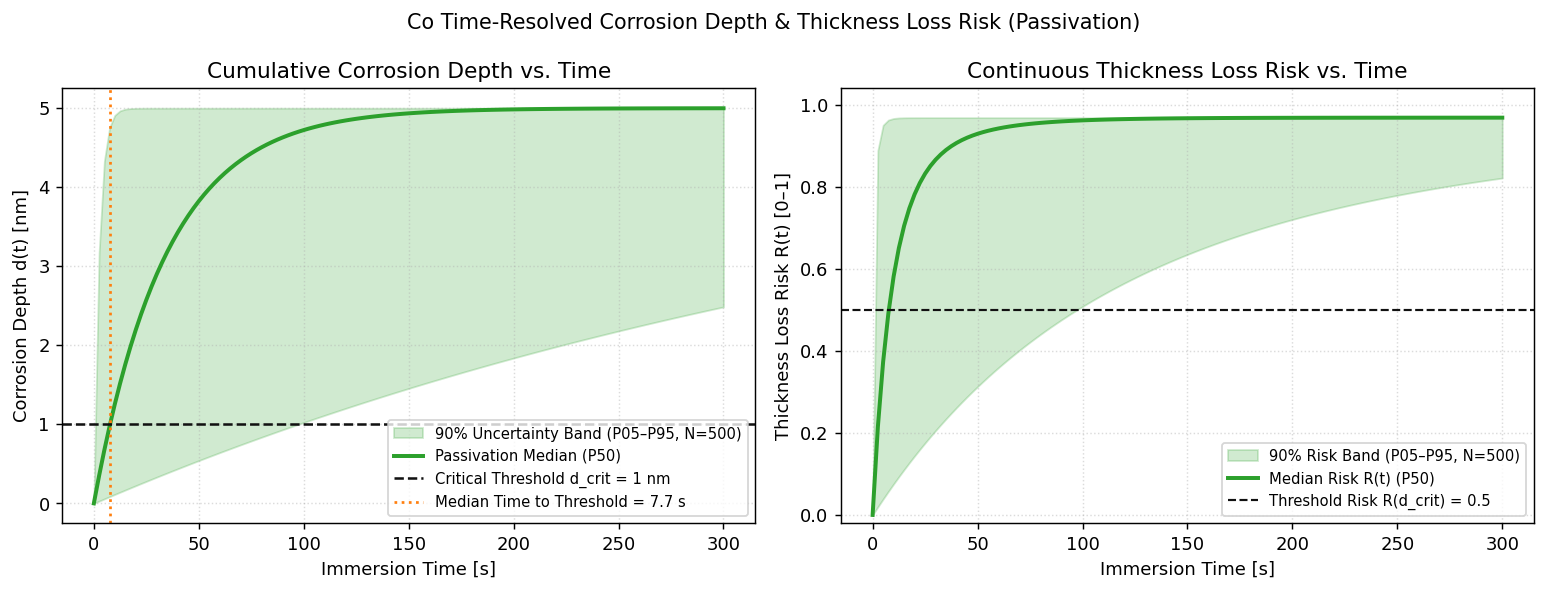

In [5]:
predictor = HybridMLPredictor(model_family="random_forest", n_estimators=60, random_state=42)
predictor.fit(seed_db)

q_co = MLFeatureQuery(metal="Co", pH=4.0, temperature_C=25.0, oxidizer_type="H2O2", oxidizer_concentration=1.0, acid_type="citric acid", acid_concentration=50.0)
q_cu = MLFeatureQuery(metal="Cu", pH=4.0, temperature_C=25.0, oxidizer_type="H2O2", oxidizer_concentration=1.0, acid_type="citric acid", acid_concentration=50.0)

mc_galv = propagate_galvanic_uncertainty_monte_carlo(
    predictor.predict(q_co),
    predictor.predict(q_cu),
    cathode_to_anode_area_ratio=2.0,
    n_draws=500,
    seed=42,
    material_properties=seed_db.material_properties,
)

mc_kinetics = propagate_kinetics_uncertainty_monte_carlo(
    mc_galv,
    times_s,
    model="passivation",
    d_crit_nm=1.0,
    d_max_nm=5.0,
)

t_sum = mc_kinetics.time_to_threshold_summary
print(f"Threshold reached in {mc_kinetics.threshold_reached_fraction*100:.1f}% of MC draws")
print(
    f"Time to Threshold (d_crit=1.0 nm): P05={t_sum['p05']:.1f} s, "
    f"Median={t_sum['p50']:.1f} s, P95={t_sum['p95']:.1f} s (mean={t_sum['mean']:.1f} +/- {t_sum['std']:.1f} s)"
)
print(
    f"Depth @ 300s: P05={mc_kinetics.depth_p05_nm[-1]:.2f} nm, "
    f"P50={mc_kinetics.depth_p50_nm[-1]:.2f} nm, P95={mc_kinetics.depth_p95_nm[-1]:.2f} nm "
    f"(Median Tier: {mc_kinetics.median_risk_tiers[-1]})"
)

fig, axes = plot_kinetics_and_risk(mc_kinetics)
